# 06 · Similarity search

A club that loses a player looks for one who plays the same way, and as well, within a budget.
This notebook builds that search from the profiles (`02_player_profiles.ipynb`,
`03_possession_value.ipynb`) and the style axes (`05_role_discovery.ipynb`), and tests it before
using it.

1. **How alike.** Which way of measuring the distance between two players finds a player again
   in another sample of their own matches.
2. **What similarity follows.** Whether a player's nearest players are teammates, from the same
   league or in the same recorded position more often than chance, and how the search fares with
   fewer minutes.
3. **Replacements.** The search: the players nearest a player, filtered by age, league, market
   value, foot and side, with what they share; shown for the most valuable players who changed
   club for 2016/17, and set against the signings clubs made.

**Players:** the 1,335 outfield players with a profile, each compared within their comparison
group.

**Data:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (events, lineups), 2015/16,
the four complete leagues; market values from Transfermarkt. Only aggregated results are shown,
as StatsBomb's licence requires. Tables are built by `make model`; see `docs/DATA_DICTIONARY.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

from football_scouting.analysis.market import market_players, team_bootstrap
from football_scouting.analysis.outcomes import season_clubs
from football_scouting.analysis.profiles import (
    KEYS,
    LABELS,
    POSSESSION,
    match_counts,
    recording_context,
    rescale,
    summed_columns,
)
from football_scouting.analysis.profiles import place as place_profile
from football_scouting.analysis.roles import axes_of, style_matches
from football_scouting.analysis.roles import place as place_style
from football_scouting.analysis.similarity import (
    FOOT,
    coordinates,
    fit_block,
    in_common,
    listed,
    nearest,
    own_rank,
    profile_gaps,
    search_points,
    search_values,
    similar,
    style_ends,
)
from football_scouting.analysis.style import SUMMED
from football_scouting.config import load_config
from football_scouting.model.database import connect_readonly
from football_scouting.plots import GREY, OKABE_ITO, credit, position_colors, use_style

cfg = load_config()
con = connect_readonly(cfg)
use_style()

OUTFIELD = list(cfg.profiles)
GROUP_NAMES = {g.code: g.name for g in cfg.comparison_groups}
COLORS = position_colors(cfg)
GROUP_COLORS = {g: COLORS["W" if g == "AMW" else g] for g in OUTFIELD}

## 1. How alike

Two players are alike if they play the same way and as well: their style and their profile. Each
is a block of numbers, standardised over the group's regulars (900 minutes or more in the group's
positions) and scaled so that the two blocks weigh the same whatever their number of columns
(`analysis.similarity`); the distance between two players is measured across both. A good
distance tells players apart by what is stable in them, not by the noise of a season: it finds a
player again in another sample of their own matches.

- **The halves.** Each player's matches are dealt alternately, in date order, into two halves
  (the matches in their group's positions and the others separately, so that each half has half
  of each). Players with 900 minutes or more in their group's positions in each half are tested.
  Each half goes through the season's steps on the season's terms: the recording context, the
  possession adjustment, the shrinkage with the season's K and group mean, the season's axes and
  standardisation (`profiles.place`, `roles.place`).
- **The test.** For each player, the other halves of every tested player of the group are ranked
  by distance from the player's half, both ways round: how often the nearest is the player's own
  (top 1), how often it is among the five nearest (top 5), and its median rank. By chance the top
  1 would come once in as many times as there are players.
- **The versions.**
  - (a) the style axes alone;
  - (b) the profile alone (the twelve statistics, shrunk);
  - (c) style and profile, equal weight, Euclidean;
  - (d) the same, with the profile block whitened by its correlations among the regulars (a
    Mahalanobis distance): passes and progressive passes, which move together, count once;
  - (e) the style descriptors (shrunk) in place of the axes, with the profile.
- **The rule**, fixed before any result: between (c) and (d), the one with the higher top-1 rate
  over all tested players, both ways round; the Euclidean (c) if the 95% interval of the
  difference (2,000 resamples of players within group) includes 0. (a), (b) and (e) are
  references: what each block brings, and what the axes leave out of the descriptors.

Then a harder test (section 1.3): players who changed team in January, their matches at one club
against those at the other.

### 1.1 The halves

In [2]:
players = con.sql("SELECT * FROM profile_players").df().set_index("player_id")
group = players.comparison_group
tables = {
    t: con.sql(f"SELECT * FROM {t}").df()
    for t in ("profile_values", "profile_statistics", "profile_recording", "style_values",
              "style_descriptors", "style_loadings", "style_scores", "style_recording")
}  # fmt: skip
counts = match_counts(con, cfg, {m for ms in cfg.profiles.values() for m in ms})
counts = counts[counts.player_id.isin(players.index)]
counts = rescale(counts, group, recording_context(counts, cfg), tables["profile_recording"])
rows = style_matches(con, cfg, group)  # the matches in the group's positions
rows = rescale(rows, group, recording_context(rows, cfg), tables["style_recording"])
PROFILE_SUMS, STYLE_SUMS = summed_columns(counts), [*SUMMED, "minutes", *POSSESSION]
style_minutes = tables["style_scores"].groupby("player_id").minutes.first()
regulars = style_minutes.index[style_minutes >= cfg.compared.minutes]


def season_values(g):
    """A group's season values, block by block (rows: the group's players)."""
    ids = group.index[group == g]
    out = {}
    for block, (table, column, value) in {
        "profile": ("profile_values", "statistic", "shrunk"),
        "descriptors": ("style_values", "descriptor", "shrunk"),
        "style": ("style_scores", "axis", "score"),
    }.items():
        t = tables[table][tables[table].comparison_group == g]
        out[block] = t.pivot(index="player_id", columns=column, values=value).loc[ids]
    return out


def placed(g, profile_sums, style_sums):
    """A group's blocks from sums of players' matches (rows: players), on the season's terms."""
    profile = place_profile(profile_sums, g, tables["profile_statistics"])
    descriptors = place_style(style_sums, g, tables["style_descriptors"])
    scores = axes_of(tables["style_descriptors"], tables["style_loadings"], g).scores(descriptors)
    return {"profile": profile, "descriptors": descriptors, "style": scores}


SEASON = {g: season_values(g) for g in OUTFIELD}
season_sums = (counts.groupby("player_id")[PROFILE_SUMS].sum(),
               rows.groupby("player_id")[STYLE_SUMS].sum())  # fmt: skip
gap = 0.0
for g in OUTFIELD:
    ids = group.index[group == g]
    again = placed(g, season_sums[0].loc[ids], season_sums[1].loc[ids])
    for block, values in again.items():
        gap = max(gap, (values - SEASON[g][block][values.columns]).abs().max().max())
assert gap < 1e-9  # the steps placed again give the processed tables back

in_group = pd.MultiIndex.from_frame(counts[KEYS]).isin(pd.MultiIndex.from_frame(rows[KEYS]))
counts = counts.assign(in_group=in_group).sort_values(
    ["player_id", "in_group", "match_date", "match_id"]
)
counts["half"] = counts.groupby(["player_id", "in_group"]).cumcount() % 2
rows = rows.merge(counts[[*KEYS, "half"]], on=KEYS, validate="1:1")
halves = (counts.groupby(["player_id", "half"])[PROFILE_SUMS].sum(),
          rows.groupby(["player_id", "half"])[STYLE_SUMS].sum())  # fmt: skip
half_minutes = halves[1].minutes.unstack()
tested = half_minutes.index[half_minutes.min(axis=1) >= cfg.compared.minutes]
per_half = half_minutes.loc[tested].median().median()
per_half_all = halves[0].minutes.unstack().loc[tested].median().median()
print(
    f"The season's sums placed again give the processed tables back (largest difference "
    f"{gap:.0e}). Players with 900 minutes or more in their group's positions in each half: "
    f"{len(tested)} ("
    + ", ".join(f"{GROUP_NAMES[g].lower()} {n}"
                for g, n in group.loc[tested].value_counts().reindex(OUTFIELD).items())
    + f"); median minutes per half in those positions {per_half:,.0f}, all matches "
    f"{per_half_all:,.0f}."
)  # fmt: skip

The season's sums placed again give the processed tables back (largest difference 7e-15). Players with 900 minutes or more in their group's positions in each half: 576 (centre-backs 156, full-backs 114, central midfielders 152, attacking midfielders and wingers 96, centre-forwards 58); median minutes per half in those positions 1,250, all matches 1,329.


### 1.2 The versions

In [3]:
VERSIONS = {  # block: whitened
    "(a) Style": {"style": False},
    "(b) Profile": {"profile": False},
    "(c) Style and profile": {"style": False, "profile": False},
    "(d) Style and profile, Mahalanobis": {"style": False, "profile": True},
    "(e) Descriptors and profile": {"descriptors": False, "profile": False},
}
DRAWS, SEED = 2000, 2016


def space(g, blocks):
    """A space's blocks for a group ({block: whitened}), fitted on the regulars' season values."""
    return {
        block: fit_block(SEASON[g][block].loc[SEASON[g][block].index.isin(regulars)], whiten=w)
        for block, w in blocks.items()
    }


ranks = []
for g in OUTFIELD:
    ids = tested[group.loc[tested] == g]
    parts = [placed(g, halves[0].xs(h, level="half").loc[ids],
                    halves[1].xs(h, level="half").loc[ids]) for h in (0, 1)]  # fmt: skip
    for v in VERSIONS:
        a, b = (coordinates(space(g, VERSIONS[v]), p) for p in parts)
        ranks.append(pd.DataFrame({
            "group": g, "version": v, "player_id": ids, "candidates": len(ids),
            "ab": own_rank(a, b).to_numpy(), "ba": own_rank(b, a).to_numpy(),
        }))  # fmt: skip
ranks = pd.concat(ranks, ignore_index=True)
ranks["top1"] = ((ranks.ab == 1).astype(float) + (ranks.ba == 1)) / 2
ranks["top5"] = ((ranks.ab <= 5).astype(float) + (ranks.ba <= 5)) / 2


def resampled(values):
    """Means of per-player `values` (rows: group, player; columns: versions) over resamples of
    players within group: one row per draw, columns (group or "All", version)."""
    rng = np.random.default_rng(SEED)
    rows_of = {g: np.flatnonzero(values.index.get_level_values(0) == g) for g in OUTFIELD}
    out = []
    for _ in range(DRAWS):
        pick = {g: rng.choice(r, len(r)) for g, r in rows_of.items()}
        means = {g: values.iloc[r].mean() for g, r in pick.items()}
        means["All"] = values.iloc[np.concatenate(list(pick.values()))].mean()
        out.append(pd.concat(means))
    return pd.DataFrame(out)


top1 = ranks.pivot_table(index=["group", "player_id"], columns="version", values="top1")[
    list(VERSIONS)
]
draws = resampled(top1)
point = pd.concat({g: top1.loc[g].mean() for g in OUTFIELD} | {"All": top1.mean()})
both_ways = ranks.melt(id_vars=["group", "version", "candidates"], value_vars=["ab", "ba"])
summary = pd.DataFrame({
    "Top 1": point["All"],
    "95% interval": [f"{draws['All', v].quantile(0.025):.0%} to "
                     f"{draws['All', v].quantile(0.975):.0%}" for v in VERSIONS],
    "Top 5": ranks.groupby("version").top5.mean(),
    "Median rank": both_ways.groupby("version").value.median(),
    "Mean rank, share of the players": (both_ways.value / both_ways.candidates)
    .groupby(both_ways.version).mean(),
}).loc[list(VERSIONS)]  # fmt: skip
chance = (1 / ranks.drop_duplicates("player_id").candidates).mean()
display(
    summary.style.format({"Top 1": "{:.1%}", "Top 5": "{:.1%}", "Median rank": "{:.1f}",
                          "Mean rank, share of the players": "{:.1%}"})
    .set_caption(f"A player's other half among every tested player's, both ways round, "
                 f"{len(tested)} players (top 1 by chance: {chance:.1%})")
)  # fmt: skip

c, d = "(c) Style and profile", "(d) Style and profile, Mahalanobis"
difference = draws["All", d] - draws["All", c]
low, high = difference.quantile([0.025, 0.975])
kept = d if low > 0 else c
assert kept == c
print(
    f"The rule: (d) less (c), top 1 over the {len(tested)} players, "
    f"{point['All', d] - point['All', c]:+.1%} ({low:+.1%} to {high:+.1%}); {kept} is kept."
)

,Top 1,95% interval,Top 5,Median rank,"Mean rank, share of the players"
version,,,,,
(a) Style,25.3%,22% to 28%,60.6%,4.0,6.8%
(b) Profile,43.1%,40% to 47%,72.1%,2.0,4.6%
(c) Style and profile,58.9%,56% to 62%,86.1%,1.0,2.7%
"(d) Style and profile, Mahalanobis",52.5%,49% to 56%,80.7%,1.0,3.5%
(e) Descriptors and profile,73.0%,70% to 76%,92.3%,1.0,1.9%


The rule: (d) less (c), top 1 over the 576 players, -6.4% (-9.2% to -3.8%); (c) Style and profile is kept.


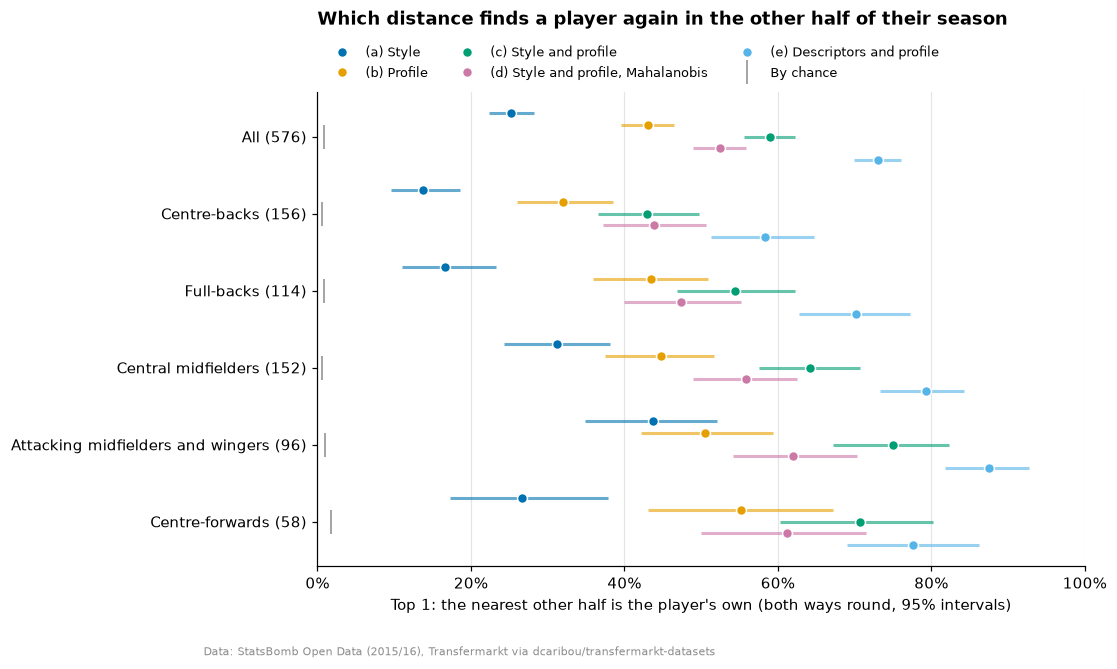

In [4]:
rows_shown = ["All", *OUTFIELD]
labels = {"All": f"All ({len(tested)})"} | {
    g: f"{GROUP_NAMES[g]} ({(group.loc[tested] == g).sum()})" for g in OUTFIELD
}
fig, ax = plt.subplots(figsize=(9, 5.6))
offsets = np.linspace(0.3, -0.3, len(VERSIONS))
for i, v in enumerate(VERSIONS):
    y = -np.arange(len(rows_shown)) + offsets[i]
    lo = [draws[r, v].quantile(0.025) for r in rows_shown]
    hi = [draws[r, v].quantile(0.975) for r in rows_shown]
    ax.hlines(y, lo, hi, color=OKABE_ITO[i], lw=2, alpha=0.6)
    ax.plot([point[r, v] for r in rows_shown], y, "o", ms=6.5, color=OKABE_ITO[i], label=v,
            markeredgecolor="white", markeredgewidth=1)  # fmt: skip
by_chance = {"All": chance} | {g: 1 / (group.loc[tested] == g).sum() for g in OUTFIELD}
ax.plot([by_chance[r] for r in rows_shown], -np.arange(len(rows_shown)), "|", ms=16,
        color=GREY, label="By chance")  # fmt: skip
ax.set_yticks(-np.arange(len(rows_shown)), [labels[r] for r in rows_shown])
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", color="#E5E5E5")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Top 1: the nearest other half is the player's own (both ways round, 95% intervals)")
ax.set_title("Which distance finds a player again in the other half of their season", pad=44)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8.5)
credit(fig)
plt.show()

### 1.3 Players who changed team

A player's two halves share a team, and so do the team's other players: some of what makes a
half find its other half may be the team's way of playing. The players with 450 minutes or more
in their group's positions at each of two pool teams (they changed team in January) are tested
with their matches at their first club against those at their second, each ranked among the
other halves of the tested players of the group (less those who changed team) and the player's
own other sample. The same players' alternating halves, ranked the same way, are the comparison.
Their samples are shorter than the tested players' halves.

In [5]:
MOVER_MINUTES = 450
by_team = rows.groupby(["player_id", "team_id"]).agg(minutes=("minutes", "sum"),
                                                     first=("match_date", "min"))  # fmt: skip
by_team = by_team[by_team.minutes >= MOVER_MINUTES].reset_index()
by_team = by_team.sort_values(["player_id", "first"])
clubs = by_team[by_team.player_id.map(by_team.player_id.value_counts()) >= 2].copy()
assert clubs.player_id.value_counts().max() == 2
clubs["club"] = clubs.groupby("player_id").cumcount()
movers = pd.Index(clubs.player_id.unique())
at_clubs = (
    counts.merge(clubs[["player_id", "team_id", "club"]], on=["player_id", "team_id"])
    .groupby(["player_id", "club"])[PROFILE_SUMS].sum(),
    rows.merge(clubs[["player_id", "team_id", "club"]], on=["player_id", "team_id"])
    .groupby(["player_id", "club"])[STYLE_SUMS].sum(),
)  # fmt: skip
assert len(counts[counts.player_id.isin(movers)].merge(clubs, on=["player_id", "team_id"])) == (
    counts.player_id.isin(movers).sum()
)  # no match at a third club


def part(sums, level, h, ids):
    return [s.xs(h, level=level).loc[ids] for s in sums]


moved = []
for g in OUTFIELD:
    m = movers[group.loc[movers] == g]
    others = tested[(group.loc[tested] == g) & ~tested.isin(m)]
    other_halves = [placed(g, *part(halves, "half", h, others)) for h in (0, 1)]
    samples = {
        "At the two clubs": [placed(g, *part(at_clubs, "club", h, m)) for h in (0, 1)],
        "Alternating halves": [placed(g, *part(halves, "half", h, m)) for h in (0, 1)],
    }
    for v in VERSIONS:
        blocks = space(g, VERSIONS[v])
        pool = [coordinates(blocks, h) for h in other_halves]
        for design, (s0, s1) in samples.items():
            a, b = coordinates(blocks, s0), coordinates(blocks, s1)
            moved.append(pd.DataFrame({
                "group": g, "version": v, "design": design, "player_id": m,
                "candidates": len(others) + 1,
                "ab": own_rank(a, pd.concat([pool[1], b])).to_numpy(),
                "ba": own_rank(b, pd.concat([pool[0], a])).to_numpy(),
            }))  # fmt: skip
moved = pd.concat(moved, ignore_index=True)
moved_ways = moved.melt(id_vars=["version", "design"], value_vars=["ab", "ba"])
table = pd.concat({
    "Top 1": moved_ways.assign(hit=moved_ways.value == 1).groupby(["version", "design"]).hit.mean(),
    "Top 5": moved_ways.assign(hit=moved_ways.value <= 5).groupby(["version", "design"]).hit.mean(),
    "Median rank": moved_ways.groupby(["version", "design"]).value.median(),
}, axis=1).unstack("design").loc[list(VERSIONS)]  # fmt: skip
display(
    table.style.format("{:.0%}", subset=["Top 1", "Top 5"]).format("{:.1f}", subset="Median rank")
    .set_caption(f"{len(movers)} players who changed team: their matches at each club against "
                 "their alternating halves")
)  # fmt: skip
sample_minutes = pd.DataFrame({
    "clubs": at_clubs[1].minutes.groupby(level="player_id").min(),
    "halves": halves[1].minutes.loc[movers].groupby(level="player_id").min(),
})  # fmt: skip
print(
    f"{len(movers)} players ("
    + ", ".join(f"{GROUP_NAMES[g].lower()} {n}"
                for g, n in group.loc[movers].value_counts().reindex(OUTFIELD).dropna().items())
    + f"), each ranked among {moved.candidates.min()} to {moved.candidates.max()} samples. Minutes "
    f"in the group's positions in the shorter sample, median: {sample_minutes.clubs.median():,.0f} "
    f"at a club, {sample_minutes.halves.median():,.0f} in an alternating half."
)  # fmt: skip

22 players (centre-backs 4, full-backs 2, central midfielders 6, attacking midfielders and wingers 5, centre-forwards 5), each ranked among 57 to 155 samples. Minutes in the group's positions in the shorter sample, median: 703 at a club, 839 in an alternating half.


### What section 1 shows

- **Style and profile together find a player again 59% of the time** (top 1, against 0.9% by
  chance; 86% among the five nearest), more than the profile alone (43%) or the style axes alone
  (25%): each block holds what the other misses.
- **The Euclidean distance is kept**, by the rule: whitening the profile block lowers the top 1
  by 6.4 points (−9.2 to −3.8). Whitening gives the profile's small directions, differences
  between statistics that move together and mostly noise over half a season, as much weight as
  its main ones.
- **The axes leave stable style out.** With the descriptors in place of the axes, a player is
  found again 73% of the time (70% to 76%), more in every group: centre-backs 58% against 43%,
  full-backs 70% against 54%, central midfielders 79% against 64%, attacking midfielders and
  wingers 88% against 75%, centre-forwards 78% against 71%. The three or four axes keep what a
  group's players share; what they leave of the descriptors is less shared but as stable.
- **The search compares players by their descriptors and their profile**, equal weight,
  Euclidean (e): it finds a player again more often than the axes and the profile (c) over all
  players, in every group and across clubs. The rule chose between two ways of weighing the
  profile beside the axes; (e) shows that the axes leave out stable style the search needs. The
  axes stay to say how two players are alike, by the names of their ends.
- **Centre-backs are the hardest to tell apart**, attacking midfielders and wingers the easiest,
  whatever the version.
- **The team carries part of the likeness.** The 22 players who changed team in January are found
  again across their two clubs half as often as across alternating halves (25% against 50% with
  style and profile, a median rank of 9 against 1.5; 34% against 64% with the descriptors), on
  somewhat shorter samples (a median of 703 minutes against 839). Section 2 measures how often a
  player's nearest players are teammates.

## 2. What similarity follows

A distance that finds a player again can still bring other players close for reasons a club
would not pick them for, and it is only as good as the samples it reads. Two checks, on the
search's distance (the descriptors and the profile, section 1):

- **The nearest players** (2.1). Each regular's five nearest regulars of their group, on the
  season's values: how often they are teammates (they played for the same team), from the same
  league (where each played most), in the same line (central midfielders: defensive or central;
  attacking midfielders and wingers: attacking midfield, wide midfield or wing; centre-forwards:
  alone or in a pair) and on the same side (left or right), against the share among all the
  group's other regulars, which is what five players drawn at random would give. A player's line
  and side are those of the position they spent most time in among their group's positions. The
  same with each block alone shows which one carries a likeness. 95% intervals from 2,000
  resamples of whole teams (each player with the team they played most for in their group's
  positions).
- **Fewer minutes** (2.2). From one half of each tested player's season (section 1), matches are
  drawn at random until they reach 270, 450, 675 or 900 minutes in the group's positions (20
  draws, each half in turn) and placed on the season's terms. The short sample is tested as a
  query (does it find the player's other half among every tested player's?) and as a candidate
  (is it found from the other half, among the other players' halves?).
  - **The rule**, fixed before any result: young players (under 23 on 30 June 2016) with 450 to
    899 minutes in their group's positions join the candidates of section 3, marked, if at 450
    minutes the top 5 (both ways round, over all tested players) is at least half of what it is
    at 900.
  - **A check**: how many of the other players' five nearest a short sample comes in, among
    their full halves (five on average for a full half, by construction). Shrunk towards the
    group's mean, a short sample can sit near many players without being like them.

### 2.1 The nearest players

In [6]:
K, SEARCH = 5, "(e) Descriptors and profile"
SPACES = {
    "Descriptors and profile": VERSIONS[SEARCH],
    "Descriptors alone": {"descriptors": False},
    "Profile alone": {"profile": False},
}
members = {m: c.code for c in cfg.comparison_groups for m in c.members}
time_in = con.sql(
    "SELECT player_id, team_id, position, position_group, sum(seconds) AS seconds "
    "FROM player_positions GROUP BY ALL"
).df()
time_in = time_in[time_in.player_id.isin(players.index)]
time_in = time_in[time_in.position_group.map(members) == group.loc[time_in.player_id].to_numpy()]


def most(column):
    """Each player's value of `column` with the most time in their group's positions."""
    t = time_in.groupby(["player_id", column]).seconds.sum().reset_index()
    return t.sort_values(["seconds", column]).groupby("player_id")[column].last()


def line(g, position):
    """The line of a recorded position within its comparison group (None if the group has one)."""
    if g == "CM":
        return "Defensive" if "Defensive" in position else "Central"
    if g == "AMW":
        if "Attacking" in position:
            return "Attacking midfield"
        return "Wing" if "Wing" in position else "Wide midfield"
    if g == "CF":
        return "Alone" if position == "Center Forward" else "In a pair"
    return None


regular = pd.DataFrame({"group": group, "league": players.league, "position": most("position"),
                        "team": most("team_id")}).loc[regulars]  # fmt: skip
regular["line"] = [line(g, p) for g, p in zip(regular.group, regular.position, strict=True)]
regular["side"] = regular.position.str.split().str[0].where(lambda s: s.isin(["Left", "Right"]))
teams = counts[counts.player_id.isin(regulars)].groupby("player_id").team_id.agg(frozenset)
print(f"{len(regulars):,} regulars, {(teams.map(len) > 1).sum()} of them at two teams.")
for column in ("line", "side"):
    n = regular.dropna(subset=column).groupby("group")[column].value_counts()
    print(f"{column.capitalize()}s: " + "; ".join(
        f"{GROUP_NAMES[g].lower()} " + ", ".join(f"{v.lower()} {k}" for v, k in n[g].items())
        for g in OUTFIELD if g in n.index.get_level_values("group")
    ) + ".")  # fmt: skip

1,176 regulars, 70 of them at two teams.
Lines: central midfielders defensive 176, central 108; attacking midfielders and wingers wing 159, wide midfield 51, attacking midfield 43; centre-forwards alone 94, in a pair 55.
Sides: centre-backs right 130, left 112; full-backs left 120, right 120; central midfielders right 120, left 110; attacking midfielders and wingers left 109, right 102; centre-forwards right 32, left 23.


In [7]:
KINDS = {"Teammates": "team", "Same league": "league", "Same line": "line", "Same side": "side"}


def shared(values):
    """Pairs of players sharing a value (a missing value shares nothing)."""
    v = values.to_numpy()
    return (v[:, None] == v[None, :]) & pd.notna(v)[:, None]


near = []
for g in OUTFIELD:
    ids = regulars[group.loc[regulars] == g]
    who = regular.loc[ids]
    pairs = {kind: shared(who[column]) for kind, column in KINDS.items()}
    pairs["Teammates"] = np.array([[not a.isdisjoint(b) for b in teams.loc[ids]]
                                   for a in teams.loc[ids]])  # fmt: skip
    for p in pairs.values():
        np.fill_diagonal(p, False)
    for name, blocks in SPACES.items():
        points = coordinates(space(g, blocks), {b: SEASON[g][b].loc[ids] for b in blocks})
        five = nearest(points, K)
        at = ids.get_indexer(five.to_numpy().ravel()).reshape(five.shape)
        for kind, column in KINDS.items():
            asked = who[column].notna().to_numpy()
            listed_pairs = pairs[kind][np.arange(len(ids))[:, None], at]
            others, sharing = len(ids) - 1, pairs[kind].sum(axis=1)
            near.append(pd.DataFrame({
                "space": name, "group": g, "kind": kind, "player_id": ids,
                "team": who.team.to_numpy(),
                "nearest": listed_pairs.mean(axis=1),
                "chance": sharing / others,
                "any": listed_pairs.any(axis=1),  # one or more of the five, and by chance:
                "any_chance": 1 - np.prod([(others - sharing - i) / (others - i) for i in range(K)],
                                          axis=0),
            })[asked])  # fmt: skip
near = pd.concat(near, ignore_index=True)
wide = near.pivot_table(index=["group", "team", "player_id"], columns=["space", "kind"],
                        values=["nearest", "chance"])  # fmt: skip


def times_chance(r):
    """The mean share among the five nearest over the mean share by chance, for the players at
    rows `r` of `wide`, by group and over all: a series indexed by space, kind and group."""
    sub = wide.iloc[r]
    means = sub.groupby(level="group").mean()
    means.loc["All"] = sub.mean()
    return (means["nearest"] / means["chance"]).unstack()


times = times_chance(np.arange(len(wide)))
times_draws = team_bootstrap(times_chance, wide.index.get_level_values("team"), DRAWS, SEED)

shares = near[near.space == "Descriptors and profile"]
shares = (
    pd.concat([shares.assign(group="All"), shares])
    .groupby(["group", "kind"])[["nearest", "chance"]]
    .mean()
)
shares = shares.unstack("kind").swaplevel(axis=1)[list(KINDS)].loc[["All", *OUTFIELD]]
shares = shares.rename(columns={"nearest": "Nearest five", "chance": "By chance"})
shares.columns.names = [None, None]
shares.index = [f"All ({len(regulars):,})"] + [
    f"{GROUP_NAMES[g]} ({(regular.group == g).sum()})" for g in OUTFIELD
]
display(
    shares.style.format("{:.1%}", na_rep="–")
    .set_caption(f"The search's five nearest regulars (descriptors and profile), "
                 f"{len(regulars):,} regulars: shares against chance")
)  # fmt: skip
lists = near[(near.space == "Descriptors and profile") & (near.kind == "Teammates")]
print(f"Lists of five with a teammate in them: {lists['any'].mean():.0%}, by chance "
      f"{lists.any_chance.mean():.0%}.")  # fmt: skip

Lists of five with a teammate in them: 14%, by chance 5%.


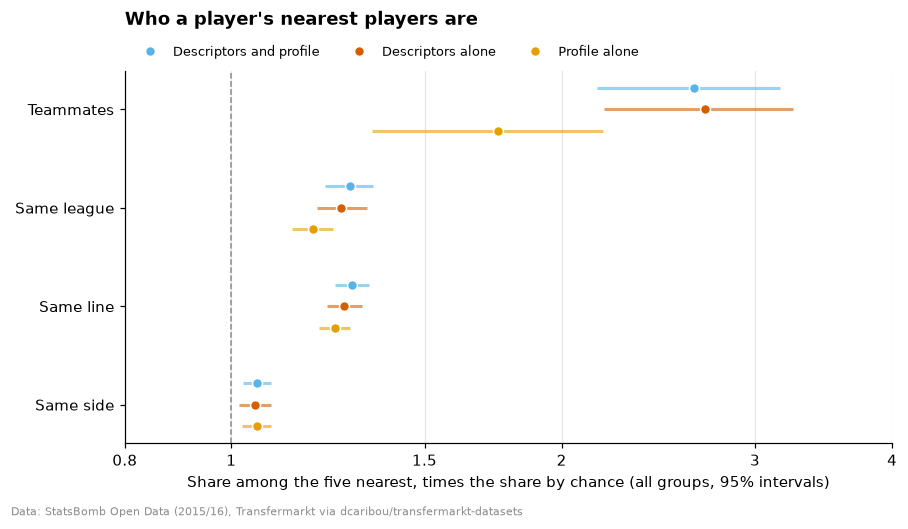

Descriptors and profile, times chance over all groups: teammates 2.64 (2.15 to 3.16), same league 1.28 (1.22 to 1.35), same line 1.29 (1.24 to 1.33), same side 1.06 (1.03 to 1.09).
Descriptors alone, times chance over all groups: teammates 2.70 (2.19 to 3.25), same league 1.26 (1.20 to 1.33), same line 1.27 (1.22 to 1.32), same side 1.05 (1.02 to 1.09).
Profile alone, times chance over all groups: teammates 1.75 (1.34 to 2.18), same league 1.19 (1.14 to 1.24), same line 1.24 (1.20 to 1.28), same side 1.06 (1.02 to 1.09).


In [8]:
SPACE_COLORS = dict(zip(SPACES, [OKABE_ITO[4], OKABE_ITO[5], OKABE_ITO[1]], strict=True))
fig, ax = plt.subplots(figsize=(9, 4.4))
offsets = np.linspace(0.22, -0.22, len(SPACES))
for i, (name, color) in enumerate(SPACE_COLORS.items()):
    y = -np.arange(len(KINDS)) + offsets[i]
    est = [times[name, kind, "All"] for kind in KINDS]
    lo = [times_draws[name, kind, "All"].quantile(0.025) for kind in KINDS]
    hi = [times_draws[name, kind, "All"].quantile(0.975) for kind in KINDS]
    ax.hlines(y, lo, hi, color=color, lw=2, alpha=0.6)
    ax.plot(est, y, "o", ms=6.5, color=color, label=name, markeredgecolor="white",
            markeredgewidth=1)  # fmt: skip
ax.axvline(1, color=GREY, lw=1, ls="--")
ax.set_xscale("log")
ax.set_xticks([0.8, 1, 1.5, 2, 3, 4], ["0.8", "1", "1.5", "2", "3", "4"])
ax.minorticks_off()
ax.set_yticks(-np.arange(len(KINDS)), list(KINDS))
ax.grid(axis="x", color="#E5E5E5")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share among the five nearest, times the share by chance (all groups, 95% intervals)")
ax.set_title("Who a player's nearest players are", pad=30)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8.5)
credit(fig)
plt.show()
for name in SPACES:
    print(f"{name}, times chance over all groups: " + ", ".join(
        f"{kind.lower()} {times[name, kind, 'All']:.2f} "
        f"({times_draws[name, kind, 'All'].quantile(0.025):.2f} to "
        f"{times_draws[name, kind, 'All'].quantile(0.975):.2f})" for kind in KINDS
    ) + ".")  # fmt: skip

### 2.2 Fewer minutes

In [9]:
MINUTES, SHORT_DRAWS = (270, 450, 675, 900), 20
SAMPLES = [*(f"{m} minutes" for m in MINUTES), "Full half"]
search = {g: space(g, VERSIONS[SEARCH]) for g in OUTFIELD}
ids_of = {g: tested[group.loc[tested] == g] for g in OUTFIELD}
full = {g: [coordinates(search[g], placed(g, *part(halves, "half", h, ids_of[g]))) for h in (0, 1)]
        for g in OUTFIELD}  # fmt: skip


def tried(g, h, sample, sums, s):
    """The ranks of sample `s` (coordinates) of half `h`, against the group's full halves."""
    other, same = full[g][1 - h], full[g][h]
    return pd.DataFrame({
        "group": g, "sample": sample, "half": h, "player_id": ids_of[g],
        "reached": sums[1].minutes.xs(h, level="half").loc[ids_of[g]].to_numpy(),
        "query": own_rank(s, other).to_numpy(),
        "candidate": own_rank(other, same, own=s).to_numpy(),
        "listed": listed(other, same, K, own=s).to_numpy(),
    })  # fmt: skip


short = [tried(g, h, "Full half", halves, full[g][h]) for g in OUTFIELD for h in (0, 1)]
mine, mine_rows = counts[counts.player_id.isin(tested)], rows[rows.player_id.isin(tested)]
rng = np.random.default_rng(SEED)
for _ in range(SHORT_DRAWS):
    drawn = mine.assign(order=rng.random(len(mine))).sort_values(["player_id", "half", "order"])
    in_position = drawn.minutes.where(drawn.in_group, 0.0)
    before = in_position.groupby([drawn.player_id, drawn.half]).cumsum() - in_position
    for m in MINUTES:
        kept = drawn[before < m]  # drawn until m minutes in the group's positions
        by_half = ["player_id", "half"]
        style_sums = mine_rows.merge(kept[KEYS], on=KEYS).groupby(by_half)[STYLE_SUMS].sum()
        sums = (kept.groupby(by_half)[PROFILE_SUMS].sum(), style_sums)
        for g in OUTFIELD:
            for h in (0, 1):
                s = coordinates(search[g], placed(g, *part(sums, "half", h, ids_of[g])))
                short.append(tried(g, h, f"{m} minutes", sums, s))
short = pd.concat(short, ignore_index=True)
again = short[short["sample"] == "Full half"].pivot(
    index="player_id", columns="half", values="query"
)
first = ranks[ranks.version == SEARCH].set_index("player_id").loc[again.index]
assert (again[0] == first.ab).all() and (again[1] == first.ba).all()  # section 1's ranks

In [10]:
ways = short.melt(id_vars=["group", "sample", "player_id"], value_vars=["query", "candidate"],
                  var_name="way", value_name="rank")  # fmt: skip
ways["way"] = ways.way.map({"query": "As a query", "candidate": "As a candidate"})


def hits(n, index="sample"):
    """The share of ranks of `n` or better, by `index` and way (and both ways round)."""
    hit = ways.assign(hit=ways["rank"] <= n)
    out = hit.pivot_table(index=index, columns="way", values="hit")
    return out[["As a query", "As a candidate"]].assign(
        **{"Both ways": hit.groupby(index).hit.mean()}
    )


table = pd.concat({
    "Minutes reached": short.groupby("sample").reached.median().to_frame("Median"),
    "Top 1": hits(1),
    "Top 5": hits(5),
    "Other players' lists": short.groupby("sample").listed.mean().to_frame("Mean"),
}, axis=1).loc[SAMPLES].rename_axis(index=None, columns=[None, None])  # fmt: skip
display(
    table.style.format("{:.1%}", subset=["Top 1", "Top 5"])
    .format("{:,.0f}", subset="Minutes reached").format("{:.2f}", subset="Other players' lists")
    .set_caption(f"Short samples of the {len(tested)} tested players against the full halves "
                 f"({SHORT_DRAWS} draws, each half in turn)")
)  # fmt: skip

top5 = ways.assign(hit=ways["rank"] <= 5).pivot_table(
    index=["group", "player_id"], columns="sample", values="hit"
)
rule_draws = resampled(top5[["450 minutes", "900 minutes"]])
ratio = rule_draws["All", "450 minutes"] / rule_draws["All", "900 minutes"]
at_450 = top5["450 minutes"].mean() / top5["900 minutes"].mean()
admitted = at_450 >= 0.5
print(
    f"The rule: top 5 at 450 minutes over top 5 at 900, both ways round, {at_450:.2f} "
    f"({ratio.quantile(0.025):.2f} to {ratio.quantile(0.975):.2f}); young players with 450 to 899 "
    f"minutes in their group's positions {'join' if admitted else 'do not join'} the candidates."
)

The rule: top 5 at 450 minutes over top 5 at 900, both ways round, 0.88 (0.87 to 0.89); young players with 450 to 899 minutes in their group's positions join the candidates.


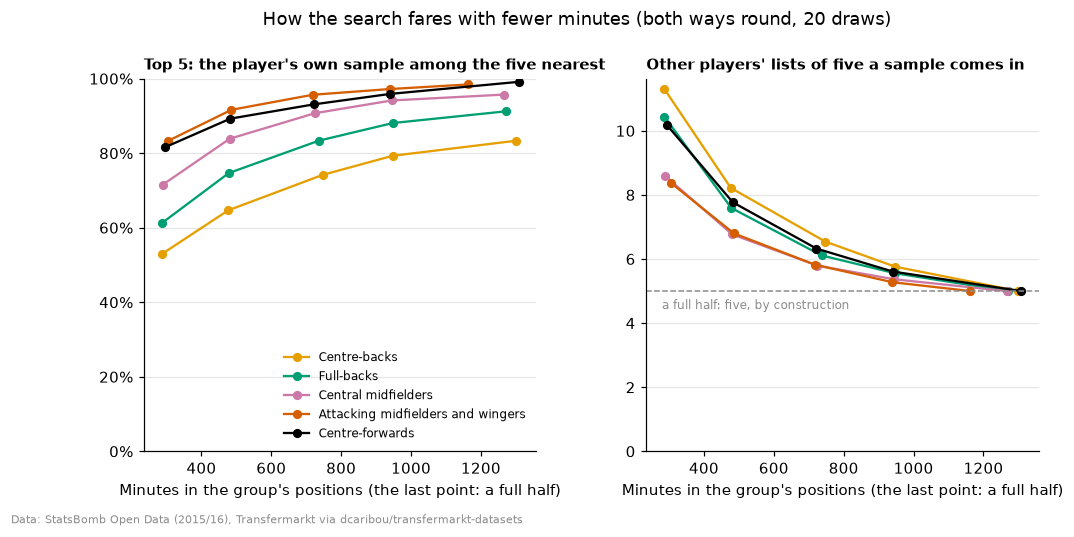

Top 5 at 450 minutes, both ways round: centre-backs 65% (a full half 83%, 156 players), full-backs 75% (a full half 91%, 114 players), central midfielders 84% (a full half 96%, 152 players), attacking midfielders and wingers 92% (a full half 98%, 96 players), centre-forwards 89% (a full half 99%, 58 players).


In [11]:
by_group = {
    "top5": hits(5, ["group", "sample"])["Both ways"].unstack(),
    "listed": short.groupby(["group", "sample"]).listed.mean().unstack(),
    "reached": short.groupby(["group", "sample"]).reached.median().unstack(),
}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), gridspec_kw={"wspace": 0.28})
for g in OUTFIELD:
    x = by_group["reached"].loc[g, SAMPLES]
    for ax, what in zip(axes, ("top5", "listed"), strict=True):
        ax.plot(x, by_group[what].loc[g, SAMPLES], "o-", color=GROUP_COLORS[g], ms=5, lw=1.5,
                label=GROUP_NAMES[g])  # fmt: skip
axes[0].set_ylim(0, 1)
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_title("Top 5: the player's own sample among the five nearest", fontsize=10)
axes[1].axhline(K, color=GREY, lw=1, ls="--")
axes[1].text(280, K - 0.25, "a full half: five, by construction", color=GREY, fontsize=8,
             va="top")  # fmt: skip
axes[1].set_ylim(0, None)
axes[1].set_title("Other players' lists of five a sample comes in", fontsize=10)
for ax in axes:
    ax.set_xlabel("Minutes in the group's positions (the last point: a full half)")
    ax.grid(axis="y", color="#E5E5E5")
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("How the search fares with fewer minutes (both ways round, 20 draws)", y=1.02)
credit(fig)
plt.show()
print("Top 5 at 450 minutes, both ways round: " + ", ".join(
    f"{GROUP_NAMES[g].lower()} {by_group['top5'].loc[g, '450 minutes']:.0%} (a full half "
    f"{by_group['top5'].loc[g, 'Full half']:.0%}, {(group.loc[tested] == g).sum()} players)"
    for g in OUTFIELD
) + ".")  # fmt: skip

### What section 2 shows

- **Teammates come up more often than chance, through style more than numbers.** 2.9% of a
  regular's five nearest are teammates, against 1.1% by chance (2.6 times, 2.2 to 3.2): 14% of
  the lists of five hold a teammate, against 5%. The descriptors alone give 2.7 times, the
  profile alone 1.75 (1.3 to 2.2): a team's way of playing shows in its players' style more than
  in how much they do. Most among centre-backs (3.9% against 1.0%) and full-backs (3.6% against
  1.0%), least among central midfielders (1.8% against 1.1%).
- **The league a little.** 32% of the nearest come from the same league, against 25% by chance
  (1.28 times, 1.22 to 1.35).
- **The line in part.** 65% of the nearest play in the same line, against 50% by chance (1.29
  times, 1.24 to 1.33): central midfielders 75% against 53% (defensive or central), attacking
  midfielders and wingers 57% against 46%, centre-forwards 59% against 53%. The search sees much
  of what the recorded line sees, but a quarter of a central midfielder's nearest play in the
  other line.
- **The side hardly.** 46% against 44% (1.06 times, 1.03 to 1.09). Read the same way from both
  flanks, a style does not say which side a player plays on (notebook 05); a club that needs a
  left-sided player filters by side or foot.
- **Fewer minutes, less precision.** The top 5 (both ways round) falls from 92% on a full half
  (a median of 1,253 minutes in the group's positions) to 90% at 900 minutes, 79% at 450 and 67%
  at 270; the top 1 from 73% to 67%, 50% and 37%. Centre-backs, with the most players to tell
  apart, fall most: 65% at 450 minutes against 83% on a full half.
- **The rule admits young players.** At 450 minutes the top 5 is 0.88 of what it is at 900
  (0.87 to 0.89), above the half the rule asks for: young players with 450 to 899 minutes in
  their group's positions join the candidates of section 3, marked.
- **But a short sample comes up too often.** Pulled towards the group's mean by the shrinkage, it
  is found more easily than it finds (top 5 at 450 minutes: 84% as a candidate, 73% as a query),
  and it comes in 7.4 of the other players' lists of five at 450 minutes and 9.8 at 270, against
  5 for a full half: one and a half and two times its share.
- **Young players are listed apart.** Mixed with the regulars, they would take about half as
  many places again as their style warrants: the search shows them in a list of their own,
  beside the regulars', each with their minutes.

## 3. Replacements

A club that loses a player looks among other clubs' players for one who plays the same way. The
search (`similarity.similar`) lists them by the distance of section 1, the descriptors and the
profile, fitted on the regulars:

- **The candidates**, in two lists (section 2.2): the regulars, and the young players (under 23 on
  30 June 2016) with 450 to 899 minutes in their group's positions, each with their minutes. The
  player's teammates (anyone who played for one of their teams in 2015/16) are left out: a club
  looks outside its squad.
- **The filters**: age, league, market value on 30 June 2016 (the back-test's market view), foot
  and side. A player's foot is the left foot's share of their passes played with either foot in
  their group's positions, left-footed from half; their side is that of the position they spent
  most time in among their group's positions (left, right, or none in the centre).
- **How a candidate is like the player**: the ends of the style axes (notebook 05) both stand at,
  by name (an end: the bottom or top third of the group's regulars on the axis), and the profile
  statistics the candidate is furthest above and below the player on, in percentile points within
  the group (higher is better: fewer ball losses, more passes).

Then the search at work:

- **Examples** (3.2). In each group, the regular with the highest market value on 30 June 2016 who
  changed club for 2016/17 (the club they played the most minutes for in Transfermarkt's
  appearances, which cover 14 first divisions, their cups and the European competitions): their
  nearest regulars until five are within a budget of half the player's value, and their three
  nearest young players. For the full-back, the same within budget and on the same side.
- **What clubs did** (3.3). When a regular left, did their club sign, in the same group, a player
  the search ranks near them? For each pair of a regular who left and a candidate of their group
  who joined the club they left for 2016/17 (from another club), the candidate's place in the
  regular's list as a share of the list (near 0: among the nearest; near 1: the furthest). By
  chance the shares spread evenly between 0 and 1: a mean of 0.5, a tenth of them in the nearest
  tenth. 95% intervals from 2,000 resamples of the clubs left, each with all its pairs; the same
  with each block alone.
- **Position and price** (3.4). The same pairs: how often the player signed plays in the same line
  (central midfielders, attacking midfielders and wingers, centre-forwards; section 2.1) and on
  the same side as the regular who left, against the share among the regular's candidates; and
  where the player signed ranks when the candidates are ordered by how close their market value
  on 30 June 2016 is to the regular's (on the log scale), as in 3.3. Clubs that replaced like for
  like by position or price would sign players of the same line and side, or near the start of
  the value order.

### 3.1 The search

In [12]:
market = market_players(con, cfg).set_index("player_id")
in_positions = style_minutes.loc[market.index]  # minutes in the group's positions
lists = pd.Series(np.select(
    [in_positions >= cfg.compared.minutes,
     (market.age < cfg.compared.young_age) & (in_positions >= cfg.compared.young_minutes)],
    ["Regulars", "Young"], default=None,
), index=market.index)  # fmt: skip
feet = rows.groupby("player_id")[["left_foot_passes", "foot_passes"]].sum()
team_names = con.sql("SELECT DISTINCT team_id, team_name FROM teams").df().set_index("team_id")
position = most("position")
who = pd.DataFrame({
    "name": market.known_as, "group": group, "list": lists,
    "teams": counts.groupby("player_id").team_id.agg(frozenset),
    "team": market.team_id.map(team_names.team_name), "league": market.league, "age": market.age,
    "minutes": in_positions, "value": market.value,
    "left_foot": feet.left_foot_passes / feet.foot_passes,
    "side": position.str.split().str[0].where(lambda s: s.isin(["Left", "Right"])),
}).loc[market.index]  # fmt: skip
who["line"] = [line(g, position[p]) for p, g in who.group.items()]
assert who.drop(columns=["list", "side", "line"]).notna().all().all()  # valued, aged

values_of = {
    g: search_values(tables["style_values"], tables["profile_values"], g) for g in OUTFIELD
}
points = {g: search_points(values_of[g], regulars) for g in OUTFIELD}
gap = max(
    (points[g] - coordinates(search[g], {b: SEASON[g][b] for b in search[g]})).abs().max().max()
    for g in OUTFIELD
)
assert gap < 1e-9  # the space of sections 1 and 2

candidates = who.dropna(subset="list")
by = candidates.group
table = pd.DataFrame({
    "Regulars": (candidates["list"] == "Regulars").groupby(by).sum(),
    "Young": (candidates["list"] == "Young").groupby(by).sum(),
    "Left-footed": (candidates.left_foot >= FOOT).groupby(by).mean(),
    "On the left": (candidates.side == "Left").groupby(by).mean(),
    "On the right": (candidates.side == "Right").groupby(by).mean(),
}).loc[OUTFIELD]  # fmt: skip
table.loc["All"] = [*table[["Regulars", "Young"]].sum(),
                    (candidates.left_foot >= FOOT).mean(), (candidates.side == "Left").mean(),
                    (candidates.side == "Right").mean()]  # fmt: skip
table.index = [GROUP_NAMES.get(g, g) for g in table.index]
display(
    table.style.format("{:,.0f}", subset=["Regulars", "Young"])
    .format("{:.0%}", subset=["Left-footed", "On the left", "On the right"])
    .set_caption("The candidates: the regulars and the young players with 450 to 899 minutes")
)  # fmt: skip
share = candidates.left_foot
print(
    f"The left foot's share of a candidate's passes played with either foot: {(share < 0.3).sum()} "
    f"below 0.3, {(share > 0.7).sum()} above 0.7, {share.between(0.3, 0.7).sum()} in between. "
    f"{len(who) - len(candidates)} profiled players are not candidates (under 900 minutes in their "
    "group's positions and not young, or under 450)."
)

,Regulars,Young,Left-footed,On the left,On the right
Centre-backs,250,6,20%,45%,52%
Full-backs,240,16,45%,51%,49%
Central midfielders,284,19,12%,40%,42%
Attacking midfielders and wingers,253,27,31%,42%,41%
Centre-forwards,149,16,16%,14%,22%
All,"1,176",84,25%,40%,42%


The left foot's share of a candidate's passes played with either foot: 908 below 0.3, 300 above 0.7, 52 in between. 75 profiled players are not candidates (under 900 minutes in their group's positions and not young, or under 450).


### 3.2 Examples

In [13]:
by_season = season_clubs(con)
club = (
    by_season[by_season.season.isin([2015, 2016])]
    .pivot(index="player_id", columns="season", values="club_id")
    .reindex(market.index)
)
moved = club.dropna().astype(int)
moved = moved[moved[2015] != moved[2016]]
departed = moved[moved.index.isin(regulars)]
club_names = con.sql("SELECT club_id, name FROM tm_clubs").df().set_index("club_id").name
pool_club = con.sql("SELECT DISTINCT team_id, club_id FROM team_map").df().set_index("team_id")
print(
    f"The club a profiled player played most for in 2015/16 is their main pool team's for "
    f"{(club[2015] == market.team_id.map(pool_club.club_id)).mean():.1%} of them; "
    f"{club[2016].isna().sum()} have no appearances in 2016/17. {len(moved)} changed club for "
    f"2016/17, {len(departed)} of them regulars ("
    + ", ".join(f"{GROUP_NAMES[g].lower()} {n}"
                for g, n in group.loc[departed.index].value_counts().reindex(OUTFIELD).items())
    + ")."
)  # fmt: skip

BUDGET, YOUNG_SHOWN = 0.5, 3  # a budget of half the player's value; young players shown


def pivot(table, column, value, g):
    t = tables[table][tables[table].comparison_group == g]
    return t.pivot(index="player_id", columns=column, values=value)


ends = {g: style_ends(pivot("style_scores", "axis", "score", g), cfg.roles.names[g], regulars)
        for g in OUTFIELD}  # fmt: skip
percentiles = {g: pivot("profile_values", "statistic", "percentile", g) for g in OUTFIELD}


def shown(g, q, found, budget):
    """The rows of `found` (from `similar`) as shown: who they are and how they are like `q`."""
    gaps = profile_gaps(percentiles[g], q, found.index)

    def gap(way):
        return (gaps[way].map(LABELS) + gaps[f"{way}_by"].map(" ({:+.0f})".format)).fillna("–")

    return pd.DataFrame({
        "Player": found.name, "Team": found.team, "League": found.league,
        "Age": found.age.astype(int), "Minutes": found.minutes, "Value (€M)": found.value / 1e6,
        "Side": found.side.fillna("–"), "Foot": np.where(found.left_foot >= FOOT, "Left", "Right"),
        "Distance": found.distance, "Style in common": in_common(ends[g], q, found.index),
        "Better on": gap("above"), "Worse on": gap("below"),
        "Within budget": np.where(found.value <= budget, "✓", ""),
    }).set_index([found["list"].rename("List"), found.place.rename("Place")])  # fmt: skip


def styled(frame, caption):
    return frame.style.format({"Minutes": "{:,.0f}", "Value (€M)": "{:.1f}",
                               "Distance": "{:.2f}"}).set_caption(caption)  # fmt: skip


examples = {g: who.value.loc[departed.index[group.loc[departed.index] == g]].idxmax()
            for g in OUTFIELD}  # fmt: skip
for g, q in examples.items():
    me, budget = who.loc[q], BUDGET * who.at[q, "value"]
    found = similar(points[g], who, q, n=None)
    first = found[found["list"] == "Regulars"]
    first = first[(first.value <= budget).cumsum().shift(fill_value=0) < 5]
    rows_shown = pd.concat([first, found[found["list"] == "Young"].head(YOUNG_SHOWN)])
    display(styled(shown(g, q, rows_shown, budget), (
        f"{GROUP_NAMES[g]}: {me['name']} ({me.team}, {int(me.age)}, €{me.value / 1e6:.0f}M, "
        f"{me.minutes:,.0f} minutes; {', '.join(e for e in ends[g].loc[q] if e)}), to "
        f"{club_names[moved.at[q, 2016]]} for 2016/17. Budget €{budget / 1e6:.1f}M."
    )))  # fmt: skip
    joined = moved.index[(moved[2016] == moved.at[q, 2015]) & (group.loc[moved.index] == g)]
    signed = [
        f"{who.at[s, 'name']} ({who.at[s, 'team']}), {found.at[s, 'place']} of "
        f"{(found['list'] == found.at[s, 'list']).sum()} {found.at[s, 'list'].lower()}"
        for s in joined.intersection(found.index)
    ]  # fmt: skip
    print(f"{club_names[moved.at[q, 2015]]} signed: " + ("; ".join(signed) or "no candidate of "
          "the group") + ".")  # fmt: skip

The club a profiled player played most for in 2015/16 is their main pool team's for 99.1% of them; 224 have no appearances in 2016/17. 351 changed club for 2016/17, 306 of them regulars (centre-backs 61, full-backs 64, central midfielders 63, attacking midfielders and wingers 67, centre-forwards 51).


Paris Saint-Germain signed: no candidate of the group.


US Sassuolo signed: no candidate of the group.


Juventus FC signed: Miralem Pjanić (AS Roma), 48 of 277 regulars.


Manchester United signed: no candidate of the group.


SSC Napoli signed: no candidate of the group.


In [14]:
q = examples["FB"]
on_side = similar(points["FB"], who, q, n=5, max_value=BUDGET * who.at[q, "value"],
                  side=who.at[q, "side"])  # fmt: skip
on_side = on_side[(on_side["list"] == "Regulars") | (on_side.place <= YOUNG_SHOWN)]
display(styled(shown("FB", q, on_side, BUDGET * who.at[q, "value"]), (
    f"{who.at[q, 'name']}: the nearest within budget who play on the {who.at[q, 'side'].lower()}"
)))  # fmt: skip

### 3.3 What clubs did

In [15]:
SEARCH_SPACE = "Descriptors and profile"  # the search's, of the spaces of section 2.1
in_space = {(name, g): search_points({b: values_of[g][b] for b in blocks}, regulars)
            for name, blocks in SPACES.items() for g in OUTFIELD}  # fmt: skip
pairs, teammates = [], 0
for q, old in departed[2015].items():
    g = group.loc[q]
    joined = moved.index[(moved[2016] == old) & (group.loc[moved.index] == g)]
    joined = joined[who.loc[joined, "list"].notna().to_numpy()]
    for name in SPACES:
        found = similar(in_space[name, g], who, q, n=None)
        size = found["list"].value_counts()
        teammates += len(joined.difference(found.index)) * (name == SEARCH_SPACE)
        pairs += [{
            "space": name, "group": g, "club": old, "departed": q, "signed": s,
            "list": found.at[s, "list"],
            "share": (found.at[s, "place"] - 0.5) / size[found.at[s, "list"]],
        } for s in joined.intersection(found.index)]  # fmt: skip
pairs = pd.DataFrame(pairs)
wide = pairs.pivot(index=["club", "group", "list", "departed", "signed"], columns="space",
                   values="share")[list(SPACES)]  # fmt: skip
assert wide.notna().all().all()


def summary_of(r):
    sub = wide.iloc[r]
    return pd.concat({"Mean": sub.mean(), "Nearest tenth": (sub <= 0.1).mean()})


estimate = summary_of(np.arange(len(wide)))
club_draws = team_bootstrap(summary_of, wide.index.get_level_values("club"), DRAWS, SEED)


def interval_of(draws, stat, name, fmt):
    low, high = draws[stat, name].quantile([0.025, 0.975])
    return f"{low:{fmt}} to {high:{fmt}}"


table = pd.DataFrame({
    "Mean share": estimate["Mean"],
    "95% interval": [interval_of(club_draws, "Mean", n, ".2f") for n in SPACES],
    "Median share": wide.median(),
    "In the nearest tenth": estimate["Nearest tenth"],
    "95% interval ": [interval_of(club_draws, "Nearest tenth", n, ".0%") for n in SPACES],
}).loc[list(SPACES)]  # fmt: skip
display(
    table.style.format({"Mean share": "{:.2f}", "Median share": "{:.2f}",
                        "In the nearest tenth": "{:.1%}"})
    .set_caption(f"Where the players a club signed rank in the list of the regular who left, "
                 f"{len(wide)} pairs (by chance: a mean of 0.50, 10% in the nearest tenth)")
)  # fmt: skip
keys = wide.index.to_frame()
print(
    f"{len(wide)} pairs: {keys.departed.nunique()} regulars who left, {keys.club.nunique()} clubs, "
    f"{keys.signed.nunique()} players signed ("
    + ", ".join(f"{n} {k.lower()}" for k, n in keys["list"].value_counts().items())
    + f"); {teammates} more pairs left out, the player signed a teammate in 2015/16. Mean share "
    "by group (the search's space): "
    + ", ".join(f"{GROUP_NAMES[g].lower()} {wide[SEARCH_SPACE].xs(g, level='group').mean():.2f} "
                f"({(keys.group == g).sum()} pairs)" for g in OUTFIELD)
    + "; by list: "
    + ", ".join(f"{k.lower()} {wide[SEARCH_SPACE].xs(k, level='list').mean():.2f}"
                for k in ("Regulars", "Young"))
    + "."
)  # fmt: skip

,Mean share,95% interval,Median share,In the nearest tenth,95% interval
space,,,,,
Descriptors and profile,0.50,0.46 to 0.54,0.47,8.2%,4% to 12%
Descriptors alone,0.49,0.45 to 0.54,0.49,13.3%,8% to 18%
Profile alone,0.51,0.47 to 0.55,0.50,7.2%,4% to 10%


195 pairs: 137 regulars who left, 58 clubs, 136 players signed (176 regulars, 19 young); 13 more pairs left out, the player signed a teammate in 2015/16. Mean share by group (the search's space): centre-backs 0.52 (34 pairs), full-backs 0.50 (43 pairs), central midfielders 0.50 (37 pairs), attacking midfielders and wingers 0.47 (58 pairs), centre-forwards 0.54 (23 pairs); by list: regulars 0.49, young 0.57.


### 3.4 Position and price

In [16]:
shared = []
for q, signed in wide.index.to_frame(index=False).groupby("departed").signed:
    found = similar(points[group.loc[q]], who, q, n=None)
    for s in signed:
        listed_with = found[found["list"] == found.at[s, "list"]]
        gap = (np.log(listed_with.value) - np.log(who.at[q, "value"])).abs()
        row = {
            "departed": q,
            "signed": s,  # ties share their places
            "value": ((gap < gap[s]).sum() + (gap == gap[s]).sum() / 2) / len(listed_with),
        }
        for column in ("line", "side"):
            if pd.notna(mine := who.at[q, column]):
                row[column] = float(who.at[s, column] == mine)
                row[f"{column}_chance"] = (listed_with[column] == mine).mean()
        shared.append(row)
shared = wide.index.to_frame(index=False).merge(pd.DataFrame(shared), validate="1:1")


def shared_of(r):
    sub = shared.iloc[r]
    out = {}
    for column in ("line", "side"):
        asked = sub.dropna(subset=column)
        out[column, "signed"] = asked[column].mean()
        out[column, "chance"] = asked[f"{column}_chance"].mean()
    out["value", "Mean"] = sub.value.mean()
    out["value", "Nearest tenth"] = (sub.value <= 0.1).mean()
    return pd.Series(out)


shared_estimate = shared_of(np.arange(len(shared)))
shared_draws = team_bootstrap(shared_of, shared.club.to_numpy(), DRAWS, SEED)
table = pd.DataFrame({
    "Pairs": [shared[c].notna().sum() for c in ("line", "side")],
    "Players signed": [shared_estimate[c, "signed"] for c in ("line", "side")],
    "By chance": [shared_estimate[c, "chance"] for c in ("line", "side")],
    "Times chance": [shared_estimate[c, "signed"] / shared_estimate[c, "chance"]
                     for c in ("line", "side")],
    "95% interval": [
        "{:.2f} to {:.2f}".format(*(shared_draws[c, "signed"] / shared_draws[c, "chance"])
                                  .quantile([0.025, 0.975]))
        for c in ("line", "side")
    ],
}, index=["Same line", "Same side"])  # fmt: skip
display(
    table.style.format({"Players signed": "{:.0%}", "By chance": "{:.0%}",
                        "Times chance": "{:.2f}"})
    .set_caption("The players signed and the regular who left: the same line and side")
)  # fmt: skip
full_backs = shared[shared.group == "FB"]
ratio = who.value.loc[shared.signed].to_numpy() / who.value.loc[shared.departed].to_numpy()
print(
    f"Full-backs on the same side: {full_backs.side.mean():.0%}, by chance "
    f"{full_backs.side_chance.mean():.0%} ({len(full_backs)} pairs). Ordered by market value, "
    f"closest first: the player signed at a mean share of {shared_estimate['value', 'Mean']:.2f} "
    f"({interval_of(shared_draws, 'value', 'Mean', '.2f')}; 0.5 by chance), "
    f"{shared_estimate['value', 'Nearest tenth']:.0%} in the nearest tenth "
    f"({interval_of(shared_draws, 'value', 'Nearest tenth', '.0%')}; 10% by chance). The player "
    f"signed was worth a median of {np.median(ratio):.2f} times the regular who left (quartiles "
    f"{np.quantile(ratio, 0.25):.2f} and {np.quantile(ratio, 0.75):.2f})."
)  # fmt: skip

,Pairs,Players signed,By chance,Times chance,95% interval
Same line,118,49%,50%,0.98,0.83 to 1.14
Same side,149,42%,45%,0.94,0.78 to 1.10


Full-backs on the same side: 51%, by chance 50% (43 pairs). Ordered by market value, closest first: the player signed at a mean share of 0.37 (0.33 to 0.41; 0.5 by chance), 16% in the nearest tenth (11% to 21%; 10% by chance). The player signed was worth a median of 0.75 times the regular who left (quartiles 0.41 and 1.45).


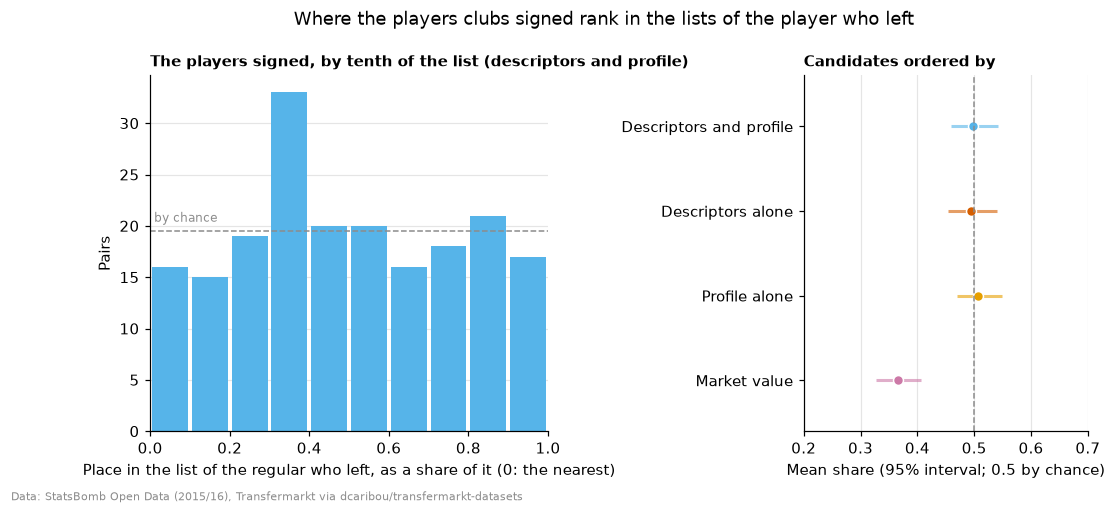

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.4, 1],
                                                                "wspace": 0.75})  # fmt: skip
tenths = np.minimum((wide[SEARCH_SPACE] * 10).astype(int), 9)
counts_of = tenths.value_counts().reindex(range(10), fill_value=0)
axes[0].bar(np.arange(10) / 10 + 0.05, counts_of, width=0.09,
            color=SPACE_COLORS[SEARCH_SPACE])  # fmt: skip
axes[0].axhline(len(wide) / 10, color=GREY, lw=1, ls="--")
axes[0].text(0.01, len(wide) / 10 + 0.6, "by chance", color=GREY, fontsize=8, va="bottom")
axes[0].set_axisbelow(True)
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("Place in the list of the regular who left, as a share of it (0: the nearest)")
axes[0].set_ylabel("Pairs")
axes[0].set_title("The players signed, by tenth of the list (descriptors and profile)",
                  fontsize=10)  # fmt: skip
orders = {name: (estimate["Mean", name], club_draws["Mean", name], SPACE_COLORS[name])
          for name in SPACES} | {
    "Market value": (shared_estimate["value", "Mean"], shared_draws["value", "Mean"], OKABE_ITO[3])
}  # fmt: skip
y = -np.arange(len(orders))
for i, (mean, draws_of, color) in enumerate(orders.values()):
    axes[1].hlines(y[i], *draws_of.quantile([0.025, 0.975]), color=color, lw=2, alpha=0.6)
    axes[1].plot(mean, y[i], "o", ms=6.5, color=color, markeredgecolor="white", markeredgewidth=1)
axes[1].axvline(0.5, color=GREY, lw=1, ls="--")
axes[1].set_yticks(y, list(orders))
axes[1].set_ylim(y[-1] - 0.6, 0.6)
axes[1].set_xlim(0.2, 0.7)
axes[1].set_xlabel("Mean share (95% interval; 0.5 by chance)")
axes[1].set_title("Candidates ordered by", fontsize=10)
for ax in axes:
    ax.grid(axis="y" if ax is axes[0] else "x", color="#E5E5E5")
    ax.grid(axis="x" if ax is axes[0] else "y", visible=False)
fig.suptitle("Where the players clubs signed rank in the lists of the player who left",
             y=1.02)  # fmt: skip
credit(fig)
plt.show()

### What section 3 shows

- **The lists read as the player's type.** Paul Pogba's five nearest regulars are advanced,
  ball-carrying central midfielders (Fredy Guarín, Juraj Kucka, Piotr Zieliński, Emmanuel
  Agyemang-Badu, Bryan Dabo), two of them long passers as well; Gonzalo Higuaín's are Daniel
  Sturridge, Karim Benzema, Jermain Defoe and Romelu Lukaku, with Harry Kane sixth. Each row says
  how a candidate is alike (the axis ends both stand at) and where they differ most (a statistic
  each way).
- **Alike is not as valued.** The five nearest regulars are worth a median of €5M beside David
  Luiz (€30M), €2M beside Šime Vrsaljko (€13M), €7.5M beside Pogba (€70M), €4.5M beside Memphis
  Depay (€25M) and €25M beside Higuaín (€60M): a budget of half the player's value leaves out
  none to two of the five. The search finds players who play the same way, not the market's
  equals; the gaps say where a candidate falls short.
- **The side needs the filter.** Vrsaljko plays on the right; four of the six regulars nearest
  play on the left, all left-footed. Filtered by side, the list is of right-backs (Juanfran,
  Alan Hutton, Roberto Rosales, Eros Pisano, Andrea Rispoli). As section 2 found, a style read
  the same way from both flanks does not say which side a player plays on.
- **Clubs did not sign the players the search lists.** In 195 pairs of a regular who left and a
  player of their group their club signed for 2016/17 (137 regulars, 58 clubs), the player
  signed sits at a mean share of 0.50 of the list (0.46 to 0.54), where chance puts them, and
  8% of them in the nearest tenth (4% to 12%) against 10%. The descriptors alone give 0.49 and
  13% (8% to 18%), the profile alone 0.51 and 7%; no group strays far from chance (0.47 to
  0.54). Juventus, after Pogba left, signed Miralem Pjanić: 48th of 277 regulars.
- **Nor by position, but near their price.** The player signed plays in the same line as the
  regular who left 49% of the time, against 50% by chance (0.98 times, 0.83 to 1.14), and on the
  same side 42% against 45% (0.94 times, 0.78 to 1.10); full-backs 51% against 50%. Ordered by
  how close their market value is to the regular's, the players signed come early: a mean share
  of 0.37 (0.33 to 0.41), 16% in the nearest tenth (11% to 21%) against 10%. The median player
  signed was worth 0.75 times the regular who left.
- **What the pairs can say.** A pair sets each player a club signed beside each regular of the
  group it lost, and the pairs follow the club more than the player who left: full-backs signed
  play on the side of the full-back who left no more often than chance. The club may have signed
  them for another place in the group, as cover or at its own price level, which the value order
  picks up; some signings came from outside the four leagues. The pairs cannot tell whether clubs
  replace a player by style; whether the search's choices would have done better is for the case
  study. Depay left in January 2017: the rule reads the club a player played most for in the
  season.